<!--
Projeto : Agente Especialista em GRC - RAG + LLM local sobre o COSO ERM 2017
Arquivo : llama/evaluateRAG.ipynb
-->
# Avaliação do recuperador (RAG)

**Universidade Presbiteriana Mackenzie** &ndash; Faculdade de Computação e Informática
Sistemas de Informação &ndash; Inteligência Artificial (7ºK, noite) &ndash; Prof. Dr. Leandro Zerbinatti

| Integrante | RA | E-mail |
|---|---|---|
| Guilherme Martins Silva | 10417140 | 10417140@mackenzista.com.br |
| Enzo Ribeiro | 10418262 | 10418262@mackenzista.com.br |
| Pedro Nogueira Ribeiro | 10324924 | 10324924@mackenzista.com.br |

**Síntese:** mede Hit Rate, MRR e Precision@1 do pipeline de recuperação do agente (MMR com k=20 no Chroma + re-ranking com BAAI/bge-reranker-v2-m3, top 6) sobre 16 perguntas com trecho de referência, variando o threshold de similaridade de 0,75 a 0,99. A comparação com baselines está em `experimentos_N2.ipynb`.

**Histórico de alterações**

| Data | Autor | Descrição |
|---|---|---|
| 2026-02-26 | Guilherme Martins Silva | Versão inicial: conjunto de 16 perguntas, pipeline e gráficos. |
| 2026-11-15 | Enzo Ribeiro | Cabeçalho padronizado; conjunto de perguntas movido para `llama/eval_dataset.py`; `pip install` substituído pelo `requirements.txt`; figura salva em `resultados/`; notebook reexecutado com as saídas salvas. |

> Dependências: `pip install -r requirements.txt` (na raiz do repositório). Execute este notebook a partir da pasta `llama/`.

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))   # raiz do repositório -> pacote "llama"

from llama.EvaluationRAG import RAGEvaluator, EvaluationSample
from llama.eval_dataset import load_dataset
from llama.RAG.rank_context import RankContext
from llama.RAG.BuildVectorStore import PDFVectorStore

# 16 perguntas em português + trecho de referência (gabarito) do COSO ERM 2017
dataset = load_dataset("pt")
for i, s in enumerate(dataset, 1):
    print(f"{i:2d}. {s.query}")

/home/enzoribeiroz/VSCode/mackenzie/ai/ai_lab_mack/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


 1. Qual é a definição de Enterprise Risk Management?
 2. Quantos e quais sãos componentes que estruturam o framework (ERM)?
 3. O ERM deve ser integrado à estratégia?
 4. O ERM é um departamento separado?
 5. Qual a importancia da supervisão em cima do Enterprise Risk Management?
 6. Qual é o objetivo do ERM em relação ao valor?
 7. O ERM reduz surpresas organizacionais?
 8. A cultura faz parte do ERM?
 9. Como o ERM contribui para o alinhamento entre performance e risco?
10. Qual é a relação entre ERM e resiliência organizacional?
11. O ERM ajuda a identificar oportunidades além de riscos?
12. Qual o papel do componente Review and Revision?
13. Qual o papel da comunicação no ERM?
14. Como o ERM auxilia na alocação de recursos?
15. Como o ERM ajuda a gerenciar riscos em toda a entidade?
16. Qual é a definição de risco segundo o framework?


In [2]:
def build_pipeline():

    # 1. Carrega o banco e o reranker uma única vez (na inicialização)
    rag_support = PDFVectorStore()   # índice persistido em llama/RAG/db
    chroma = rag_support._load_db()

    reranker = RankContext(
        model="BAAI/bge-reranker-v2-m3",
        top_n=6
    )

    def pipeline(query: str, k: int, threshold=0.75):
        # STAGE 1: Busca MMR (Diversidade)
        # k aqui deve ser maior que o top_n do reranker para ele ter o que filtrar.
        # Se você quer 6 no final, peça 20 ou 30 para o MMR.
        initial_docs = chroma.max_marginal_relevance_search(
            query, 
            k=k,        # Quantidade para o Re-ranker analisar
            fetch_k=50,  # Quantidade que o Chroma analisa internamente
            lambda_mult=0.5
        )

        # STAGE 2: Re-ranking (Ordenação de Relevância)
        # O Re-ranker vai pegar esses 20 diversos e colocar os 6 melhores no topo
        ranked_docs = reranker.call_rank(query, initial_docs)

        # STAGE 3: Filtro Opcional de Threshold (se necessário)
        # Nota: Como o MMR não retorna score facilmente, o threshold aqui 
        # costuma ser aplicado no score do Re-ranker se o modelo permitir.
        # Por enquanto, vamos retornar os top_n ordenados:
        
        return [d.page_content for d in ranked_docs]

    return pipeline

In [3]:
# 1. Constrói o pipeline do agente (MMR + re-ranking)
pipeline = build_pipeline()

# 2. Instancia o Evaluator
evaluator = RAGEvaluator(
    pipeline_fn=pipeline,
    dataset=dataset,
    model_name="BAAI/bge-m3"
)

# 3. Roda a avaliação
# k=20 é o que o retriever (Chroma) busca antes do Reranker filtrar para top_n=6
# similarity_threshold=0.70
df = evaluator.evaluate(k=20, similarity_threshold=0.75)

INFO:RAG:🚀 Carregando embeddings...


Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-m3: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-m3'.


INFO:sentence_transformers.base.model:Loading SentenceTransformer model from BAAI/bge-m3.


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 49187.87it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

... (17 outputs left out)


🏆 Reranker ranking:
-0.7612 | {'source': '854173331-Coso-Erm-Standard-2017.txt', 'chunk_id': '854173331-Coso-Erm-Standard-2017.txt_0_chunk_61', 'doc_id': '854173331-Coso-Erm-Standard-2017.txt_0'} | [doc_id: 42d793ff-eb7e-48eb-b689-e24fe00753a2]
-1.1182 | {'source': '854173331-Coso-Erm-Standard-2017.txt', 'chunk_id': '854173331-Coso-Erm-Standard-2017.txt_0_chunk_15', 'doc_id': '854173331-Coso-Erm-Standard-2017.txt_0'} | [doc_id: 4abe14ad-9649-4189-9d2e-e44717afc964]
-3.1816 | {'doc_id': '854173331-Coso-Erm-Standard-2017.txt_0', 'chunk_id': '854173331-Coso-Erm-Standard-2017.txt_0_chunk_37', 'source': '854173331-Coso-Erm-Standard-2017.txt'} | [doc_id: 26c61511-cf2b-4f30-9508-63ca12dffb80]
-4.8438 | {'doc_id': '854173331-Coso-Erm-Standard-2017.txt_0', 'chunk_id': '854173331-Coso-Erm-Standard-2017.txt_0_chunk_9', 'source': '854173331-Coso-Erm-Standard-2017.txt'} | [doc_id: ec79314b-b144-4ef1-95b5-225d5a24e021]
-5.0117 | {'source': '854173331-Coso-Erm-Standard-2017.txt', 'doc_id': '85417333


🏆 Reranker ranking:
0.4380 | {'doc_id': '854173331-Coso-Erm-Standard-2017.txt_0', 'source': '854173331-Coso-Erm-Standard-2017.txt', 'chunk_id': '854173331-Coso-Erm-Standard-2017.txt_0_chunk_27'} | [doc_id: d4b2f9a9-a811-412d-9265-8a414b975d46]
-0.1159 | {'source': '854173331-Coso-Erm-Standard-2017.txt', 'chunk_id': '854173331-Coso-Erm-Standard-2017.txt_0_chunk_11', 'doc_id': '854173331-Coso-Erm-Standard-2017.txt_0'} | [doc_id: 7e0754d9-aab5-46de-b7b0-5ae9fcfde426]
-0.8447 | {'doc_id': '854173331-Coso-Erm-Standard-2017.txt_0', 'chunk_id': '854173331-Coso-Erm-Standard-2017.txt_0_chunk_276', 'source': '854173331-Coso-Erm-Standard-2017.txt'} | [doc_id: f0481782-4662-4709-9bf3-3baf08d1a8f9]
-0.9302 | {'source': '854173331-Coso-Erm-Standard-2017.txt', 'chunk_id': '854173331-Coso-Erm-Standard-2017.txt_0_chunk_64', 'doc_id': '854173331-Coso-Erm-Standard-2017.txt_0'} | [doc_id: 5b069436-efbb-438b-b92b-1e457102defa]
-0.9443 | {'doc_id': '854173331-Coso-Erm-Standard-2017.txt_0', 'chunk_id': '854


🏆 Reranker ranking:
-0.8037 | {'source': '854173331-Coso-Erm-Standard-2017.txt', 'doc_id': '854173331-Coso-Erm-Standard-2017.txt_0', 'chunk_id': '854173331-Coso-Erm-Standard-2017.txt_0_chunk_43'} | [doc_id: c2d31c86-9c77-46c3-966e-6aca6c005567]
-2.5137 | {'chunk_id': '854173331-Coso-Erm-Standard-2017.txt_0_chunk_42', 'source': '854173331-Coso-Erm-Standard-2017.txt', 'doc_id': '854173331-Coso-Erm-Standard-2017.txt_0'} | [doc_id: 5f16405c-190a-485e-8322-dac27f8f2ba8]
-3.0156 | {'doc_id': '854173331-Coso-Erm-Standard-2017.txt_0', 'source': '854173331-Coso-Erm-Standard-2017.txt', 'chunk_id': '854173331-Coso-Erm-Standard-2017.txt_0_chunk_57'} | [doc_id: 9cbc8527-f554-4a9e-acc6-2e6759acee44]
-3.5176 | {'source': '854173331-Coso-Erm-Standard-2017.txt', 'doc_id': '854173331-Coso-Erm-Standard-2017.txt_0', 'chunk_id': '854173331-Coso-Erm-Standard-2017.txt_0_chunk_264'} | [doc_id: d437b0db-690d-430d-937f-4f93fe8a9aa5]
-4.1680 | {'source': '854173331-Coso-Erm-Standard-2017.txt', 'chunk_id': '8541

Thres: 0.75 | HitRate: 0.938 | MRR: 0.729 | P@1: 0.562
Thres: 0.76 | HitRate: 0.938 | MRR: 0.729 | P@1: 0.562
Thres: 0.77 | HitRate: 0.812 | MRR: 0.630 | P@1: 0.500
Thres: 0.78 | HitRate: 0.750 | MRR: 0.599 | P@1: 0.500
Thres: 0.79 | HitRate: 0.688 | MRR: 0.536 | P@1: 0.438
Thres: 0.80 | HitRate: 0.688 | MRR: 0.536 | P@1: 0.438
Thres: 0.81 | HitRate: 0.625 | MRR: 0.432 | P@1: 0.312
Thres: 0.82 | HitRate: 0.625 | MRR: 0.401 | P@1: 0.250
Thres: 0.83 | HitRate: 0.562 | MRR: 0.339 | P@1: 0.188
Thres: 0.84 | HitRate: 0.500 | MRR: 0.323 | P@1: 0.188
Thres: 0.85 | HitRate: 0.500 | MRR: 0.323 | P@1: 0.188
Thres: 0.86 | HitRate: 0.438 | MRR: 0.292 | P@1: 0.188
Thres: 0.87 | HitRate: 0.438 | MRR: 0.292 | P@1: 0.188
Thres: 0.88 | HitRate: 0.438 | MRR: 0.292 | P@1: 0.188
Thres: 0.89 | HitRate: 0.438 | MRR: 0.292 | P@1: 0.188
Thres: 0.90 | HitRate: 0.438 | MRR: 0.292 | P@1: 0.188
Thres: 0.91 | HitRate: 0.438 | MRR: 0.292 | P@1: 0.188
Thres: 0.92 | HitRate: 0.438 | MRR: 0.292 | P@1: 0.188
Thres: 0.9

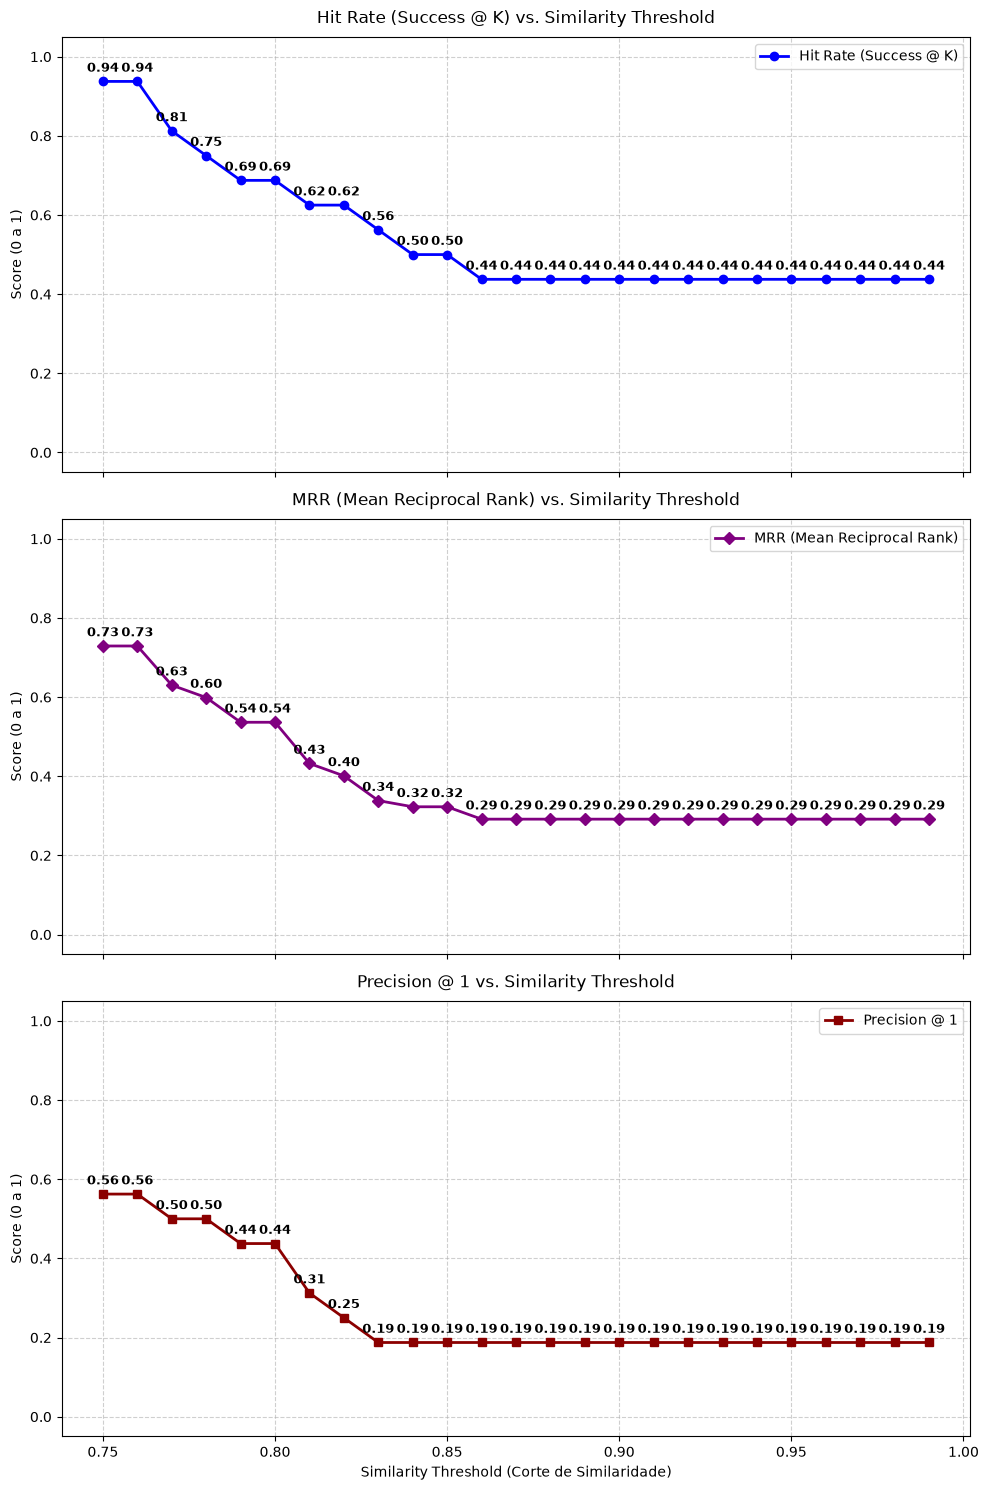

In [4]:
import matplotlib.pyplot as plt

# 1. Criamos a figura com 3 subplots verticais
fig, axs = plt.subplots(3, 1, figsize=(10, 15), sharex=True)

# 2. Atualizamos a lista de métricas para os novos nomes das colunas
# (coluna_no_df, nome_exibição, marcador, cor, offset_texto)
metrics = [
    ('hit_rate', 'Hit Rate (Success @ K)', 'o', 'blue', (0, 7)),
    ('mrr', 'MRR (Mean Reciprocal Rank)', 'D', 'purple', (0, 7)),
    ('precision_at_1', 'Precision @ 1', 's', 'darkred', (0, 7))
]

for ax, (col, label, marker, color, offset) in zip(axs, metrics):
    # Plotagem da linha
    ax.plot(df['similarity_threshold'], df[col], 
            marker=marker, label=label, color=color, linewidth=2)

    # Adicionando anotações de dados (os valores numéricos sobre os pontos)
    for i in range(len(df)):
        val = df[col].iloc[i]
        threshold = df['similarity_threshold'].iloc[i]
        ax.annotate(f'{val:.2f}', 
                    (threshold, val), 
                    textcoords="offset points", 
                    xytext=offset, 
                    ha='center', 
                    fontsize=9,
                    fontweight='bold')

    # Configurações estéticas de cada subplot
    ax.set_ylabel('Score (0 a 1)')
    ax.set_title(f'{label} vs. Similarity Threshold', fontsize=12, pad=10)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.set_ylim(-0.05, 1.05) # Garante que a escala seja sempre de 0 a 1
    ax.legend(loc='upper right')

# Eixo X comum
axs[-1].set_xlabel('Similarity Threshold (Corte de Similaridade)')

# Ajuste fino para evitar sobreposição
plt.tight_layout()
os.makedirs("resultados", exist_ok=True)
plt.savefig("resultados/fig_avaliacao_retriever.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# Ponto de operação escolhido (melhor equilíbrio entre cobertura e exigência semântica)
df[df.similarity_threshold.round(2) == 0.77]

,N° Interação,similarity_threshold,hit_rate,mrr,precision_at_1,N° Hits,N° Miss
2,2,0.77,0.8125,0.630208,0.5,13,3


In [6]:
df

,N° Interação,similarity_threshold,hit_rate,mrr,precision_at_1,N° Hits,N° Miss
0,0,0.75,0.9375,0.729167,0.5625,15,1
1,1,0.76,0.9375,0.729167,0.5625,15,1
2,2,0.77,0.8125,0.630208,0.5000,13,3
3,3,0.78,0.7500,0.598958,0.5000,12,4
4,4,0.79,0.6875,0.536458,0.4375,11,5
5,5,0.80,0.6875,0.536458,0.4375,11,5
6,6,0.81,0.6250,0.432292,0.3125,10,6
7,7,0.82,0.6250,0.401042,0.2500,10,6
8,8,0.83,0.5625,0.338542,0.1875,9,7
9,9,0.84,0.5000,0.322917,0.1875,8,8
